# 이커머스 멀티모달 데이터 분석 (A1-1)

> 이 노트북은 `0.0 문제_단계별 따라하기.md`의 순서(4~11단계)를 그대로 따른다. **각 코드 셀 위에는 그 코드가 하는 일을, 아래에는 결과 해석을 Markdown으로 적었다.** 위에서 아래로 한 번에 실행(Restart → Run All)하면 모든 결과가 재현된다.

## 목차
1. 목적과 데이터 출처
2. 환경 준비 · 데이터 로드 (4단계)
3. 데이터 품질 점검 (5단계)
4. 피처 엔지니어링: 텍스트·이미지 (8단계)
5. 결측치 처리 (6단계)
6. IQR 이상치 탐지 (7단계)
7. 통계량과 상관관계 (9단계)
8. 시각화 6종 (10단계)
9. RFM 고객 분석 (11단계)
10. 결론

## 1. 목적과 데이터 출처

**목적:** 브라질 이커머스 데이터로 상품 가격의 분포와 이상치를 파악하고, 텍스트·이미지에서 새 변수를 만들어 가격과의 관계를 보며, 고객을 RFM으로 나눠 비즈니스 인사이트를 얻는다.

| 항목 | 내용 |
|---|---|
| 데이터셋 | Brazilian E-Commerce Public Dataset by Olist |
| 원본 URL | https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce |
| 라이선스 | CC BY-NC-SA 4.0 (저작자 표시, 비상업적 이용, 동일조건변경허락) |
| 데이터 기간 | 2016년 ~ 2018년 |
| 주 분석 파일 | `olist_order_items_dataset.csv` (주문 속 상품 항목, 112,650행 × 7열) |
| 보조 파일 | `olist_products_dataset.csv`, `product_category_name_translation.csv` (상품 정보), `olist_orders_dataset.csv`, `olist_customers_dataset.csv` (RFM·월별 추이) |

**데이터의 한계 (먼저 밝힌다)**
- **상품명 텍스트가 없다.** `product_name` 대신 카테고리명 단어 수와 상품명 글자 수(`product_name_lenght`)를 사용한다.
- **상품 이미지가 없다.** 이미지 배열 분석은 별도로 가진 사진 7장으로 계산 방법을 시연하며, 실제 상품과 연결되지 않는다.
- 원본 파일은 수정하지 않고 메모리의 `df`에서만 가공한다.

## 2. 환경 준비 · 데이터 로드 (4단계)

### 2-1. 라이브러리와 경로 설정
분석에 쓸 도구를 가져오고 데이터 폴더 경로를 정한다. 노트북이 `notebooks/` 폴더에 있으면 데이터는 `../data/raw`에 있으므로 두 위치 중 존재하는 쪽을 자동으로 고른다. `sns.set_theme`은 모든 차트의 기본 모양을 정한다.

In [67]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("../data/raw") if Path("../data/raw").exists() else Path("data/raw")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

print("데이터 폴더:", DATA_DIR.resolve())
print(sorted(p.name for p in DATA_DIR.glob("*.csv")))

데이터 폴더: C:\Codyssey26\심화과정\A1-1\data\raw
['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_orders_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


### 2-2. 주 데이터 읽기
`pd.read_csv`로 주문 항목 파일을 `df`에 읽고, 크기(`shape`), 컬럼 이름(`columns`), 앞 5행(`head`)을 확인한다. 이 테이블은 **한 행이 "주문 속 상품 1개"** 이다. 따라서 `order_id` 하나로는 행을 구분할 수 없고, `order_item_id`(주문 안에서의 순번)와 함께 써야 한다.

In [35]:
df = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")

print("행과 열:", df.shape)
print("\n컬럼 이름:")
print(df.columns.tolist())
print("\n앞의 5개 행:")
print(df.head())

행과 열: (112650, 7)

컬럼 이름:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

앞의 5개 행:
                           order_id  order_item_id                        product_id                         seller_id  shipping_limit_date   price  \
0  00010242fe8c5a6d1ba2dd792cb16214              1  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202  2017-09-19 09:45:35   58.90   
1  00018f77f2f0320c557190d7a144bdd3              1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36  2017-05-03 11:05:13  239.90   
2  000229ec398224ef6ca0657da4fc703e              1  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d  2018-01-18 14:48:30  199.00   
3  00024acbcdf0a6daa1e931b038114c75              1  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4  2018-08-15 10:10:18   12.99   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1  ac6c3623068f30de03045865e4e10089  df560393f3a51e745

**해석:** 112,650행 × 7열로 파일이 오류 없이 읽혔다. 컬럼은 `order_id`, `order_item_id`, `product_id`, `seller_id`, `shipping_limit_date`(판매자의 발송 기한), `price`(상품 가격), `freight_value`(배송비)이다. 앞 5행의 `order_item_id`가 모두 1인 것은 대부분의 주문이 상품 1개짜리라는 단서이다. 가격과 배송비의 단위는 헤알(BRL)이지만 이 노트북에서는 단위를 `$`로 가정해 읽어도 해석은 같다.

## 3. 데이터 품질 점검 (5단계)

### 3-1. 구조·결측·중복 한눈에 보기
5가지를 한 셀에서 확인한다.
- `head()`: 값이 예상대로 들어 있는가
- `info()`: 컬럼별 자료형과 비어 있지 않은 값(Non-Null)의 개수
- `describe(include="all").T`: 숫자 컬럼은 평균·표준편차·사분위수, 문자열 컬럼은 `unique`(고유값 수)·`top`(최빈값)·`freq`(최빈값 횟수). 해당하지 않는 칸은 `NaN`이다.
- `isna().sum()`: 컬럼별 결측치 개수
- `duplicated().sum()`: 모든 컬럼이 같은 중복 행 수

In [70]:
print(df.head())
print("+++ Info +++")
print(df.info())
print("+++ Describe +++")
display(df.describe(include="all").T)
print("+++ Null Values & 중복행수 +++")
print(df.isna().sum().sort_values(ascending=False))
print("중복 행 수:", df.duplicated().sum())

                           order_id  order_item_id                        product_id                         seller_id shipping_limit_date   price  \
0  00010242fe8c5a6d1ba2dd792cb16214              1  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202 2017-09-19 09:45:35   58.90   
1  00018f77f2f0320c557190d7a144bdd3              1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36 2017-05-03 11:05:13  239.90   
2  000229ec398224ef6ca0657da4fc703e              1  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d 2018-01-18 14:48:30  199.00   
3  00024acbcdf0a6daa1e931b038114c75              1  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4 2018-08-15 10:10:18   12.99   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87 2017-02-13 13:57:51  199.90   

   freight_value product_category_name_english  name_word_count  name_length  
0          13.29    

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,112650,98666,8272b63d03f5f79c56e9e4120aec44ef,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_item_id,112650.0,NaN,NaN,NaN,1.197834,1.0,1.0,1.0,1.0,21.0,0.705124
product_id,112650,32951,aca2eb7d00ea1a7b8ebd4e68314663af,527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_id,112650,3095,6560211a19b47992c3666cc44a7e94c0,2033,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipping_limit_date,112650,NaN,NaN,NaN,2018-01-07 15:36:52.192685,2016-09-19 00:15:34,2017-09-20 20:57:27.500000,2018-01-26 13:59:35,2018-05-10 14:34:00.750000,2020-04-09 22:35:08,NaN
price,112650.0,NaN,NaN,NaN,120.653739,0.85,39.9,74.99,134.9,6735.0,183.633928
freight_value,112650.0,NaN,NaN,NaN,19.99032,0.0,13.08,16.26,21.15,409.68,15.806405
product_category_name_english,111023,71,bed_bath_table,11115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name_word_count,112650.0,NaN,NaN,NaN,1.84506,0.0,1.0,2.0,2.0,6.0,0.729617
name_length,112650.0,NaN,NaN,NaN,48.685894,5.0,42.0,52.0,57.0,76.0,10.075571


+++ Null Values & 중복행수 +++
product_category_name_english    1627
order_id                            0
order_item_id                       0
product_id                          0
shipping_limit_date                 0
seller_id                           0
price                               0
freight_value                       0
name_word_count                     0
name_length                         0
dtype: int64
중복 행 수: 0


**해석 (관찰 내용)**
- 결측치는 **0건**이고 중복 행도 **0건**이다. 7개 컬럼의 Non-Null 개수가 모두 112,650이다. 다만 `?`, `-`, `0` 같은 값으로 결측을 표시한 경우는 pandas가 결측으로 세지 않으므로, `describe()`의 최솟값으로 다시 확인했다.
- `order_id`의 고유값은 98,666개로 전체 행 수보다 적다. 한 주문에 상품이 여러 개인 경우가 있기 때문이며, 주문의 **90.1%가 상품 1개짜리**이다. `order_item_id`의 최댓값은 21이다.
- `price`는 0.85 ~ 6,735이고 평균 120.65가 중앙값 74.99보다 훨씬 크다. 표준편차(183.63)도 평균보다 커서 **고가 상품에 끌려 오른쪽으로 치우친 분포**이다.
- `freight_value`의 최솟값은 0.0이며 무료배송 항목으로 오류가 아니다.
- `shipping_limit_date`는 날짜인데 문자열(`str`)로 읽혔다. 다음 셀에서 날짜형으로 바꾼다.

**시사점:** 결측·중복 처리는 필요 없지만, 가격이 심하게 치우쳐 있어 이상치 점검(6장)이 중요하다.

### 3-2. 날짜 컬럼 자료형 변환
`shipping_limit_date`를 문자열에서 `datetime`으로 바꾼다. 날짜형이어야 기간 계산, 연·월 추출, 정렬이 가능하다. `errors="coerce"`는 변환할 수 없는 값을 오류 대신 `NaT`(날짜 결측)로 바꾸므로, 변환이 실패한 값이 있는지 개수로 확인한다.

In [37]:
df["shipping_limit_date"] = pd.to_datetime(df["shipping_limit_date"], errors="coerce")

print("자료형:", df["shipping_limit_date"].dtype)
print("변환 실패(NaT):", df["shipping_limit_date"].isna().sum())
print("기간:", df["shipping_limit_date"].min(), "~", df["shipping_limit_date"].max())

자료형: datetime64[us]
변환 실패(NaT): 0
기간: 2016-09-19 00:15:34 ~ 2020-04-09 22:35:08


**해석:** 변환 실패는 0건이며 발송 기한의 범위는 2016-09-19 ~ 2020-04-09이다. 이 값은 주문일이 아니라 **판매자가 택배사에 물건을 넘겨야 하는 기한**이므로, 월별 매출 추이(8장)는 주문일(`order_purchase_timestamp`)을 사용한다.

## 4. 피처 엔지니어링: 텍스트·이미지 (8단계)

> **순서 안내:** 가이드의 6단계(결측 처리)는 결측이 있는 컬럼이 있어야 연습할 수 있다. `order_items`에는 결측이 없으므로, 여기서 텍스트 변수를 먼저 만들어 결측이 생기는 컬럼(`name_length`)을 확보한 뒤 5장에서 결측을 처리한다. 이는 가이드 6-2의 안내를 따른 것이다.

### 4-1. 텍스트에서 단어 수·글자 수 변수 만들기
과제는 "상품명에서 단어 수 또는 문자열 길이를 계산"하라고 하지만 이 데이터에는 **상품명 텍스트가 없다.** 상품 정보 파일에서 쓸 수 있는 두 가지로 대체한다.
- `product_category_name`: 포르투갈어 카테고리명을 영어로 번역한 뒤 **단어 수** 계산 → `name_word_count`
- `product_name_lenght`: 상품명의 **글자 수**(이미 계산되어 제공됨, 원본 철자 `lenght` 그대로) → `name_length`

**코드의 흐름**
1. `products`와 번역표를 읽고 `merge`로 영어 카테고리명을 붙인다(`how="left"`로 `products`의 행은 모두 유지).
2. 영어 카테고리명의 `_`를 공백으로 바꿔 단어 수를 센다. 카테고리가 없으면 0이다.
3. `set_index("product_id")` 후 `map`으로 `df`의 각 행 `product_id`에 해당하는 값을 찾아 새 컬럼을 붙인다(엑셀의 VLOOKUP과 같다). `map`은 몇 번을 실행해도 컬럼이 중복되지 않는다.

In [72]:
products = pd.read_csv(DATA_DIR / "olist_products_dataset.csv")
trans = pd.read_csv(DATA_DIR / "product_category_name_translation.csv", encoding="utf-8-sig")

# 1) 카테고리명을 영어로 번역해서 붙이기
products = products.merge(trans, on="product_category_name", how="left")

# 2) 카테고리명의 단어 수 (언더스코어를 공백으로 바꿔서 센다, 비어 있으면 0)
products["name_word_count"] = (
    products["product_category_name_english"]
    .fillna("").str.replace("_", " ").str.split().str.len()
)

# 3) df(order_items)에 product_id 기준으로 컬럼 붙이기 (행 수는 그대로)
by_product = products.set_index("product_id")
df["product_category_name_english"] = df["product_id"].map(by_product["product_category_name_english"])
df["name_word_count"] = df["product_id"].map(by_product["name_word_count"])
df["name_length"] = df["product_id"].map(by_product["product_name_lenght"])

print("products 행 수:", len(products), "| 카테고리 결측 상품:", products["product_category_name"].isna().sum())
print("df 행 수:", len(df), "(112650이어야 한다)")
print("+++ describe(name_word_count, name_length) +++")
display(df[["name_word_count", "name_length"]].describe())
print(df[["product_category_name_english", "name_word_count", "name_length"]].isna().sum())

products 행 수: 32951 | 카테고리 결측 상품: 610
df 행 수: 112650 (112650이어야 한다)
+++ describe(name_word_count, name_length) +++


,name_word_count,name_length
count,112650.000000,111047.000000
mean,1.845060,48.775978
std,0.729617,10.025581
min,0.000000,5.000000
25%,1.000000,42.000000
50%,2.000000,52.000000
75%,2.000000,57.000000
max,6.000000,76.000000


product_category_name_english    1627
name_word_count                     0
name_length                      1603
dtype: int64


**해석**
- `df`의 행 수는 112,650으로 그대로이고 컬럼이 3개 늘었다(`product_category_name_english`, `name_word_count`, `name_length`).
- `name_word_count`는 0 ~ 6(평균 1.85), `name_length`는 5 ~ 76(평균 48.78)이다. 단어 수는 카테고리명이 짧아 값의 폭이 좁다.
- **결측이 생겼다.** `products` 테이블의 32,951개 상품 중 **610개(1.85%)** 는 카테고리와 상품명 길이가 모두 비어 있다. 이 상품이 주문 항목에 반영되어 `name_length`는 **1,603행**이 비었다. 영어 카테고리는 번역표에 없는 카테고리 때문에 1,627행이 비었다.
- 결측 상품의 `name_word_count`는 `fillna("")` 때문에 0으로 들어간다. 0은 "카테고리가 비어 있음"과 "단어가 0개"를 구분하지 못하는 한계가 있다.

### 4-2. 새 컬럼의 값이 예상 범위 안에 있는지 확인
새로 만든 컬럼에 말이 안 되는 값이 없는지 `assert`로 검사한다. `assert 조건`은 조건이 참이면 아무 일도 없고, 거짓이면 `AssertionError`로 멈추는 안전장치이다. 출력이 없으면 통과한 것이다. 결측(`NaN`)은 비교가 안 되므로 `dropna()`로 뺀 값만 검사한다.
- `name_word_count`: 0 이상의 정수
- `name_length`: 0보다 큼(상품명 글자 수)

In [74]:
assert df["name_word_count"].min() >= 0
assert (df["name_word_count"].dropna() % 1 == 0).all()    # 정수인지
assert df["name_length"].dropna().min() > 0
print("텍스트 변수가 예상 범위 안에 있다")

텍스트 변수가 예상 범위 안에 있다


### 4-3. 이미지 배열의 평균과 표준편차
이미지는 `(세로, 가로, 3)` 모양의 숫자 격자이다. 3은 빨강·초록·파랑(RGB) 채널이고, 값은 0(검정)~255(가장 밝음)이다. **평균은 전체적인 밝기, 표준편차는 명암 대비**를 나타낸다.

이 데이터에는 상품 이미지가 없어서 `data/raw/images/`에 둔 사진을 사용한다(없으면 NumPy로 만든 샘플 배열로 대체한다). 과제의 제한에 따라 OpenCV·Pillow 같은 이미지 처리 라이브러리는 쓰지 않고 `matplotlib.image.imread`와 NumPy만 사용한다.

**반복문을 쓰지 않는 계산:** 파일을 읽을 때만 목록을 만들고, 사진들을 같은 크기로 가운데를 잘라 하나의 4차원 배열 `(장수, 높이, 너비, 3)`으로 쌓은 뒤 `axis=(1, 2, 3)`로 **장마다 한 번에** 평균·표준편차를 구한다. 크기를 맞추려고 가장자리를 잘라내므로 원본 전체의 값과 조금 다를 수 있다. 사진에 사람이 찍혀 있어 개인정보 보호를 위해 이미지 자체는 출력하지 않는다.

In [77]:
import matplotlib.image as mpimg

IMG_DIR = DATA_DIR / "images"
img_paths = sorted(IMG_DIR.glob("*.jpg"))

if img_paths:
    arrays = [mpimg.imread(p) for p in img_paths]                  # 파일 읽기
    names = [p.name for p in img_paths]
    print("읽은 이미지 수:", len(arrays))
    print("각 배열 모양:", [a.shape for a in arrays])

    min_h = min(a.shape[0] for a in arrays)
    min_w = min(a.shape[1] for a in arrays)
    print("가장 작은 높이:", min_h, "| 가장 작은 너비:", min_w)

    def center_crop(a, h, w):
        y, x = (a.shape[0] - h) // 2, (a.shape[1] - w) // 2
        return a[y:y + h, x:x + w]

    batch = np.stack([center_crop(a, min_h, min_w) for a in arrays])
else:
    print("이미지 파일이 없어 NumPy로 만든 샘플 배열을 사용한다.")
    rng = np.random.default_rng(0)
    batch = rng.integers(0, 256, size=(7, 64, 64, 3))
    names = [f"sample_{i + 1}" for i in range(7)]

print("쌓은 배열 모양:", batch.shape, "| 자료형:", batch.dtype)

image_df = pd.DataFrame({
    "file": names,
    "image_mean": batch.mean(axis=(1, 2, 3)),     # 이미지별 평균 밝기
    "image_std": batch.std(axis=(1, 2, 3)),       # 이미지별 명암 대비
})
display(image_df.round(2))

읽은 이미지 수: 7
각 배열 모양: [(845, 1500, 3), (546, 2000, 3), (914, 2000, 3), (439, 2000, 3), (891, 2000, 3), (891, 2000, 3), (616, 2000, 3)]
가장 작은 높이: 439 | 가장 작은 너비: 1500
쌓은 배열 모양: (7, 439, 1500, 3) | 자료형: uint8


,file,image_mean,image_std
0,image_01.jpg,139.18,51.38
1,image_02.jpg,150.33,69.37
2,image_03.jpg,118.45,65.78
3,image_04.jpg,136.02,63.59
4,image_05.jpg,157.31,55.05
5,image_06.jpg,111.71,68.49
6,image_07.jpg,149.91,58.01


**해석:** 사진 7장의 평균 밝기는 111.7 ~ 157.3, 표준편차는 51.4 ~ 69.4이다. 가장 어두운 사진은 `image_06.jpg`, 가장 밝은 사진은 `image_05.jpg`이다. 두 값은 사진 한 장(숫자 1,975,500개)을 **표에 넣을 수 있는 숫자 2개로 요약**한 것이다.

**한계:** 이 값은 Olist 상품과 연결되지 않으므로(`product_id` 대응 없음) 가격 같은 변수와의 분석에는 쓰지 않았다. 계산 방법을 시연하기 위한 별도 표(`image_df`)이다. 평균·표준편차만으로는 사진에 무엇이 찍혔는지는 알 수 없다.

### 4-4. 이미지 변수의 예상 범위 확인
픽셀 값이 0~255이므로 **평균은 0~255**를 벗어날 수 없다. 표준편차는 0 이상이고, 값이 0~255 안에 있을 때 이론상 최댓값은 `(255 − 0) / 2 = 127.5`이다. 범위를 벗어나면 값 범위 변환(PNG의 0~1 vs JPEG의 0~255)이나 계산에 오류가 있다는 뜻이다.

In [78]:
assert image_df["image_mean"].between(0, 255).all()
assert image_df["image_std"].between(0, 127.5).all()
print("이미지 변수가 예상 범위 안에 있다")

이미지 변수가 예상 범위 안에 있다


## 5. 결측치 처리 (6단계)

결측치는 비어 있는 값이다. 모두 0으로 바꾸면 안 된다(0은 "값이 0"이라는 정보이고, 결측은 "값을 모름"이다).

### 5-1. 결측치 확인
결측이 1개 이상인 컬럼만 골라 많은 순서로 본다. `missing[missing > 0]`은 결측 개수가 0보다 큰 컬럼만 남기는 조건 선택이다.

In [42]:
missing = df.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))

product_category_name_english    1627
name_length                      1603
dtype: int64


**해석:** 결측이 있는 컬럼은 `product_category_name_english`(1,627행)와 `name_length`(1,603행)이다. 영어 카테고리는 **범주형 텍스트**라서 대치하지 않고 결측으로 남겨 둔다(막대그래프의 카테고리 집계에서는 결측이 자동으로 제외된다). 수치 컬럼인 `name_length`만 대치 대상이다.

### 5-2. 그룹별 대치
전체 평균 대신 **같은 그룹의 중앙값**으로 채운다. 중앙값은 극단값에 덜 흔들린다.

1. 같은 판매자(`seller_id`)의 `name_length` 중앙값으로 채운다. `groupby(...).transform("median")`은 각 행에 자기 그룹의 중앙값을 붙여 주므로 `fillna`에 바로 넣을 수 있다.
2. 그래도 남은 값(판매자의 모든 상품이 비어 있는 경우)은 전체 중앙값으로 채운다.

**왜 카테고리가 아니라 판매자로 묶는가:** `name_length`가 빈 1,603행은 카테고리도 비어 있는 바로 그 행들이다. 카테고리로 묶으면 그룹 값 자체가 비어 있어 **한 건도 채워지지 않는다.** 그룹 기준 컬럼에 결측이 없는지도 함께 확인해야 한다.

In [79]:
print("대치 전 결측:", df["name_length"].isna().sum())

# 1) 같은 판매자의 중앙값으로 채우기
df["name_length"] = df["name_length"].fillna(
    df.groupby("seller_id")["name_length"].transform("median")
)
print("판매자 그룹 대치 후:", df["name_length"].isna().sum())

# 2) 남은 값은 전체 중앙값으로 채우기
df["name_length"] = df["name_length"].fillna(df["name_length"].median())
print("전체 중앙값 대치 후:", df["name_length"].isna().sum())

대치 전 결측: 1603
판매자 그룹 대치 후: 184
전체 중앙값 대치 후: 0


**해석:** 결측 1,603행 중 판매자 그룹 중앙값으로 1,419행을 채웠고, 판매자의 상품이 전부 비어 있던 **184행은 전체 중앙값(52)** 으로 채워 결측이 0이 되었다. 중앙값 대치는 값이 전체 분포의 가운데로 몰리게 하므로 `name_length`의 퍼짐을 약간 줄인다는 한계가 있다. 이 처리 방법과 건수는 `data_source.md`에도 기록한다.

### 5-3. 처리 결과 확인
수치 컬럼의 결측이 모두 해결되었는지 다시 센다. 남아 있는 것은 범주형 영어 카테고리뿐이어야 한다.

In [80]:
print(df.isna().sum().sort_values(ascending=False))

product_category_name_english    1627
order_id                            0
order_item_id                       0
product_id                          0
shipping_limit_date                 0
seller_id                           0
price                               0
freight_value                       0
name_word_count                     0
name_length                         0
dtype: int64


## 6. IQR 이상치 탐지 (7단계)

이상치는 유난히 크거나 작은 값이다. **이상치가 항상 잘못된 데이터인 것은 아니다.** 실제 고가 상품일 수 있으므로 먼저 찾고, 이유를 검토한 다음 처리 여부를 결정한다.

IQR 방식은 가운데 50% 구간(Q1~Q3)에서 IQR의 1.5배 넘게 벗어난 값을 이상치 후보로 본다. 1977년 튜키(Tukey)가 제안한 관례이며, 1.5는 정규분포에서 약 0.7%만 걸리도록 고른 경험적 값이다.
- IQR = Q3 − Q1
- 하한 = Q1 − 1.5 × IQR, 상한 = Q3 + 1.5 × IQR

### 6-1. 탐지 함수 만들기
컬럼 하나(Series)를 받아 이상치 여부(`mask`)와 하한·상한을 돌려준다. `mask`는 하한 미만이거나 상한 초과이면 `True`인 Series이며 `|`는 "또는"이다. `multiplier`로 배수 1.5를 바꿀 수 있다.

In [81]:
def find_iqr_outliers(series, multiplier=1.5):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - multiplier * iqr
    upper = q3 + multiplier * iqr
    mask = (series < lower) | (series > upper)
    return mask, lower, upper

### 6-2. 가격에 적용
함수를 `price`에 적용하고 하한, 상한, 탐지 개수를 출력한다. `mask.sum()`은 이상치 값의 합이 아니라 `True`의 **개수**이다.

In [82]:
mask, lower, upper = find_iqr_outliers(df["price"].dropna())
print("하한:", lower)
print("상한:", upper)
print("탐지된 이상치 수:", mask.sum())

하한: -102.6
상한: 277.4
탐지된 이상치 수: 8427


### 6-3. 원본 행과 대응하는 이상치 행 꺼내기
위 `mask`는 결측을 뺀 Series로 계산했다. 원본 `df`의 행과 정확히 대응하는 결과가 필요해서 함수 없이 풀어 쓴다. `price.notna() & (...)`는 결측이 아닌 행 중에서 조건을 만족하는 행만 `True`로 만든다(이 데이터는 결측이 0이라 결과는 같다). `df.loc[outlier_mask]`로 이상치 행을 모든 컬럼으로 꺼내고, `nlargest`로 가장 비싼 5건을 본다(`head()`는 가격 순서가 아니라 원래 순서의 앞 5개이다).

In [92]:
price = df["price"]
q1 = price.quantile(0.25)
q3 = price.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_mask = price.notna() & ((price < lower) | (price > upper))
print("하한:", lower)
print("상한:", upper)     

outliers = df.loc[outlier_mask] 
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("이상치 비율:", round(outlier_mask.mean() * 100, 2), "%")
display(outliers.nlargest(5, "price")[["order_id", "product_id", "price", "freight_value", "product_category_name_english"]])

하한: -102.6
상한: 277.4
Q1: 39.9 | Q3: 134.9 | IQR: 95.0
이상치 비율: 7.48 %


,order_id,product_id,price,freight_value,product_category_name_english
3556,0812eb902a67711a1cb742b3cdaa65ae,489ae2aa008f021502940f251d4cce7f,6735.0,194.31,housewares
112233,fefacc66af859508bf1a7934eab1e97f,69c590f7ffc7bf8db97190b6cb6ed62e,6729.0,193.21,computers
107841,f5136e38d1a14a4dbd87dff67da82701,1bdf5e6731585cf01aa8169c7028d6ad,6499.0,227.66,art
74336,a96610ab360d42a2e5335a3998b4718a,a6492cc69376c469ab6f61d8f44de961,4799.0,151.34,small_appliances
11249,199af31afc78c699f0dbf71fb178d4d4,c3ed642d592594bb648ff4a04cee2747,4690.0,74.34,small_appliances


**해석**
- Q1 = 39.9, Q3 = 134.9, IQR = 95.0이므로 하한 **-102.6**, 상한 **277.4**이다. 하한이 음수라서 가격이 낮아서 걸린 값은 없고, **8,427개(7.5%)** 는 모두 상한을 넘는 고가이다.
- 정규분포라면 0.7% 정도만 걸리는데 7.5%가 걸렸다. 가격이 심하게 오른쪽으로 치우친 분포라는 뜻이며, 이 중 다수는 오류가 아니라 **실제 고가 상품**으로 보는 것이 자연스럽다. 가장 비싼 값은 6,735이고, 1,000을 넘는 항목은 844건이다.
- **처리 기준:** 근거 없이 삭제하지 않는다. 원본 `df`는 그대로 두고, 아래에서 이상치를 제외한 값과 비교만 한다.

### 6-4. 처리 전/후 분포 비교
이상치를 제외하기 전(`before`)과 후(`after`)의 가격 통계를 한 표로 비교한다. `~outlier_mask`는 이상치가 아닌 행을 고른다. 표에는 `skew`(왜도, 한쪽으로 치우친 정도)와 `변화량 = 처리 후 − 처리 전`을 더했다.

In [93]:
before = df["price"]
after = df.loc[~outlier_mask, "price"]          # 이상치 제외(비교용, 원본은 그대로)

compare = pd.DataFrame({"처리 전": before.describe(), "처리 후": after.describe()})
compare.loc["skew"] = [before.skew(), after.skew()]
compare["변화량"] = compare["처리 후"] - compare["처리 전"]
display(compare.round(2))

,처리 전,처리 후,변화량
count,112650.00,104223.00,-8427.00
mean,120.65,83.97,-36.68
std,183.63,58.58,-125.05
min,0.85,0.85,0.00
25%,39.90,38.50,-1.40
50%,74.99,69.00,-5.99
75%,134.90,118.99,-15.91
max,6735.00,277.30,-6457.70
skew,7.92,1.01,-6.91


**해석:** 평균은 120.65에서 83.97로, 표준편차는 183.63에서 58.58로 크게 줄었지만 **중앙값은 74.99에서 69.00로 조금만** 변했다. 최댓값은 6,735에서 277.30로, 왜도는 7.92에서 1.01로 낮아졌다.

**시사점:** 평균과 표준편차는 소수의 고가 상품에 크게 좌우되고 중앙값은 안정적이다. 가격의 대표값은 평균보다 **중앙값**이 적절하다. 이상치를 삭제하면 분포는 덜 치우치지만 정상적인 고가 상품 7.5%가 함께 사라지므로, 분석 목적에 따라 삭제 여부를 정해야 한다.

### 6-5. 처리 전/후 시각화
왼쪽은 상자그림(상자 = 25%~75%, 안의 선 = 중앙값, 점 = 이상치), 오른쪽은 히스토그램을 겹쳐 그렸다(`alpha=0.5` 반투명). `tick_labels`는 상자그림의 아래 이름표이다(matplotlib 3.9 이후 예전 `labels` 인자는 없어졌다).

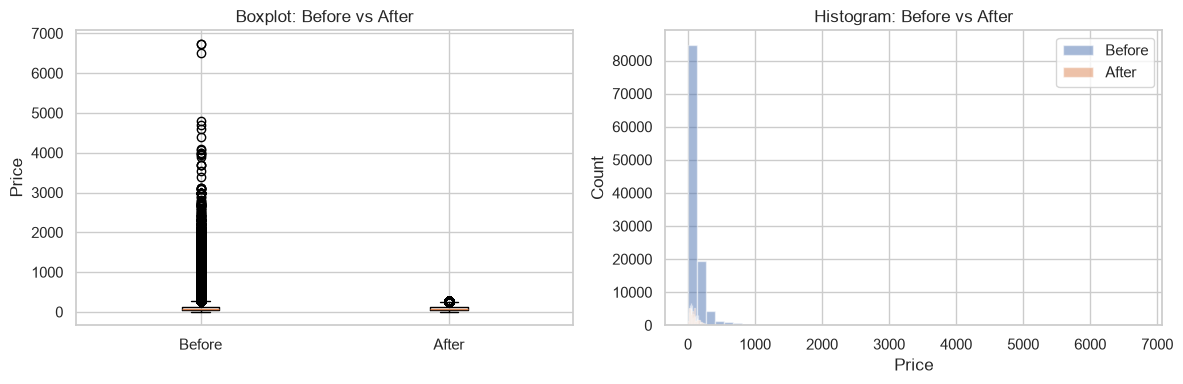

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].boxplot([before, after], tick_labels=["Before", "After"])
ax[0].set_title("Boxplot: Before vs After")
ax[0].set_ylabel("Price")
ax[1].hist(before, bins=50, alpha=0.5, label="Before")
ax[1].hist(after, bins=50, alpha=0.5, label="After")
ax[1].set_title("Histogram: Before vs After")
ax[1].set_xlabel("Price")
ax[1].set_ylabel("Count")
ax[1].legend()
plt.tight_layout()
plt.show()

**해석:** Before는 6,735까지 이어지는 이상치 때문에 상자가 거의 보이지 않을 만큼 찌그러지고, After는 상자와 분포 모양이 뚜렷하다. 두 히스토그램 모두 저가 구간에 크게 몰려 있어 **대부분 상품이 저가**임을 보여 준다.

## 7. 통계량과 상관관계 (9단계)

### 7-1. 주요 통계량
숫자형 컬럼만 골라(`select_dtypes(include="number")`) 평균, 표준편차, 최솟값, 사분위수(25/50/75%), 최댓값을 구한다. 평균과 중앙값(50%)의 차이가 크면 일부 큰 값이 평균을 끌어올린 것이다.

In [50]:
numeric_df = df.select_dtypes(include="number")
display(numeric_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
order_item_id,112650.0,1.197834,0.705124,1.00,1.00,1.00,1.00,21.00
price,112650.0,120.653739,183.633928,0.85,39.90,74.99,134.90,6735.00
freight_value,112650.0,19.990320,15.806405,0.00,13.08,16.26,21.15,409.68
name_word_count,112650.0,1.845060,0.729617,0.00,1.00,2.00,2.00,6.00
name_length,112650.0,48.685894,10.075571,5.00,42.00,52.00,57.00,76.00


**해석:** `price`는 평균 120.65, 중앙값 74.99, 표준편차 183.63로 평균이 중앙값의 약 1.6배이고, `freight_value`도 평균 19.99가 중앙값 16.26보다 크다. 두 변수 모두 오른쪽으로 치우쳐 있어 평균보다 중앙값이 대표값으로 안전하다. `order_item_id`의 중앙값과 75%가 모두 1이므로 4분의 3 이상의 항목이 주문의 첫 번째 상품이다.

### 7-2. 상관계수
상관계수는 두 수치 변수의 **선형 관계**를 −1~1로 요약한다. 1에 가까우면 함께 증가, −1에 가까우면 한쪽이 늘 때 다른 쪽이 감소, 0에 가까우면 선형 관계가 약하다. **상관관계만으로 원인과 결과를 단정할 수 없다.**

In [51]:
corr = numeric_df.corr()
display(corr.round(3))

,order_item_id,price,freight_value,name_word_count,name_length
order_item_id,1.000,-0.061,-0.029,0.029,-0.021
price,-0.061,1.000,0.414,0.030,0.017
freight_value,-0.029,0.414,1.000,0.047,0.027
name_word_count,0.029,0.030,0.047,1.000,0.046
name_length,-0.021,0.017,0.027,0.046,1.000


**해석 (최소 2쌍)**
1. **가격 ↔ 배송비: 0.414.** 가격이 높은 항목일수록 배송비도 높은 중간 정도의 양의 관계이다. 비싼 물건이 크고 무거워 운임이 오른다고 추측할 수 있지만, 무게·부피 데이터로 확인한 것은 아니므로 원인으로 단정할 수 없다.
2. **가격 ↔ 상품명 글자 수: 0.017**, **가격 ↔ 카테고리명 단어 수: 0.030.** 둘 다 0에 가까워 상품명이 길다고 가격이 높다는 선형 관계는 거의 없다. 대체 변수(카테고리명 단어 수)라서 의미가 약하다는 한계도 있다.
3. 가격 ↔ `order_item_id`는 -0.061으로 약한 음의 관계이다.

**한계:** 상관계수는 직선 관계만 요약하고 극단값(이상치)의 영향을 받는다. 가격이 심하게 치우쳐 있어 로그 변환이나 이상치 제외 시 값이 달라질 수 있다.

## 8. 시각화 6종 (10단계)

차트마다 제목과 축 레이블을 넣고, 아래에 "무엇이 보이는가 / 수치 근거 / 비즈니스 의미"를 적는다.

### 8-1. 히스토그램: 가격 분포
가격을 구간으로 나눠 각 구간에 몇 개가 있는지 보여 준다. `kde=True`는 분포의 부드러운 곡선을 겹쳐 그린다.

matplotlib(plt): 파이썬의 기본 그래프 도구입니다. 무엇이든 그릴 수 있지만 코드가 깁니다.

seaborn(sns): matplotlib 위에서 도는 통계 그래프 도구입니다. pandas DataFrame을 그대로 받고, 한 줄로 보기 좋은 그래프를 그려 줍니다.

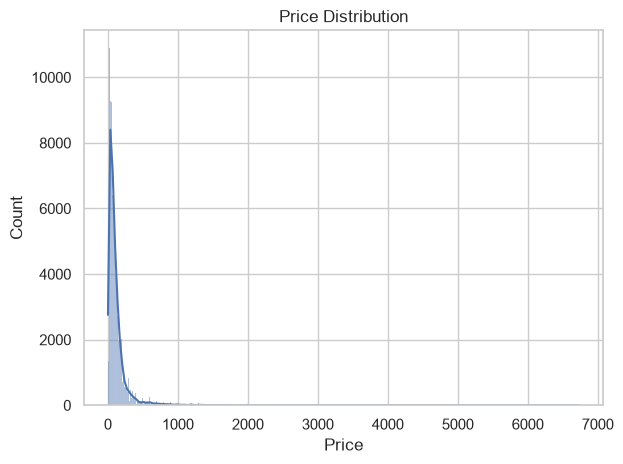

In [52]:
sns.histplot(data=df, x="price", kde=True)
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

**무엇이 보이는가:** 거의 모든 막대가 0 부근에 몰려 있고 오른쪽으로 아주 긴 꼬리가 이어진다. **수치 근거:** 중앙값 74.99, 75% 지점 134.9, 최댓값 6,735, 왜도 7.92. **의미:** 매출 대부분이 저가 상품에서 나오고 소수의 고가 상품이 평균을 끌어올린다. 가격 정책이나 목표 설정에는 평균이 아닌 중앙값이나 구간별 분석이 필요하다.

### 8-2. 박스플롯: 이상치 확인
상자는 Q1(25%)~Q3(75%), 상자 안의 선은 중앙값, 수염은 정상 범위의 끝(Q3 + 1.5 × IQR), 동그라미는 수염 밖의 이상치이다.

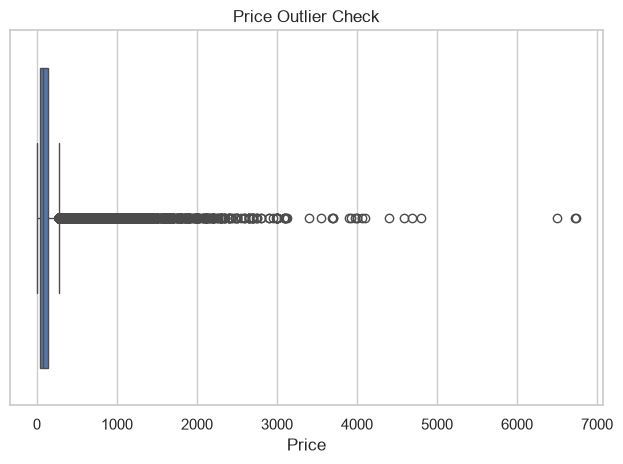

In [53]:
sns.boxplot(data=df, x="price")
plt.title("Price Outlier Check")
plt.xlabel("Price")
plt.tight_layout()
plt.show()

**무엇이 보이는가:** 상자가 0 부근에 아주 얇게 붙어 있고 수염 끝(약 277.4) 오른쪽으로 점이 빽빽하게 이어지며 몇 개는 6,735까지 멀리 떨어져 있다. **수치 근거:** 상자는 39.9 ~ 134.9, 중앙선 74.99, 이상치 8,427개(7.5%). **의미:** 이상치가 많지만 대부분은 정상적인 고가 상품이다. 이 그래프는 정상 범위 안의 분포는 읽기 어려우므로 `plt.xlim(0, 500)`이나 로그 눈금을 함께 쓰면 좋다.

### 8-3. 막대그래프: 카테고리별 데이터 수
영어 카테고리명별 주문 항목 수를 세어(`value_counts()`) 상위 10개를 그린다. 카테고리가 비어 있는 항목은 자동으로 제외된다.

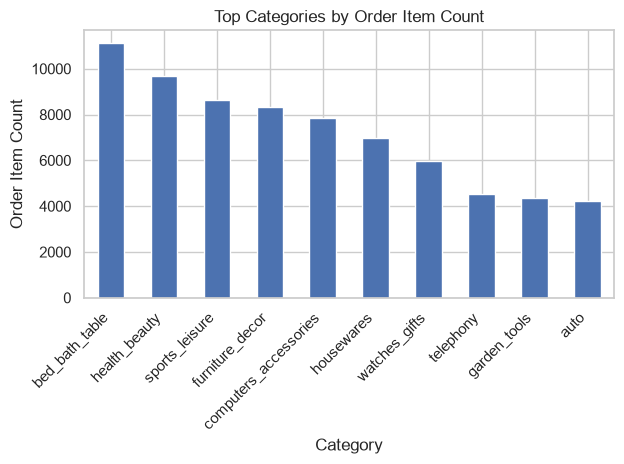

In [54]:
df["product_category_name_english"].value_counts().head(10).plot(kind="bar")
plt.title("Top Categories by Order Item Count")
plt.xlabel("Category")
plt.ylabel("Order Item Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**무엇이 보이는가:** 1위부터 순서대로 `bed_bath_table`, `health_beauty`, `sports_leisure`이며 상위 몇 개가 크게 앞선다. **수치 근거:** 1위 11,115건, 2위 9,670건, 3위 8,641건이고 상위 10개 카테고리가 전체 카테고리 71개 항목의 **64.6%** 를 차지한다. **의미:** 판매가 소수의 카테고리에 집중되어 있어 재고, 마케팅 예산, 배송 품질 관리를 이 카테고리에 우선 배분할 근거가 된다.

### 8-4. 히트맵: 상관행렬
앞에서 계산한 상관계수를 색으로 나타낸다. `annot=True`는 칸 안에 숫자를 적고, `cmap="coolwarm"`은 양의 상관은 빨강, 음의 상관은 파랑으로 칠한다.

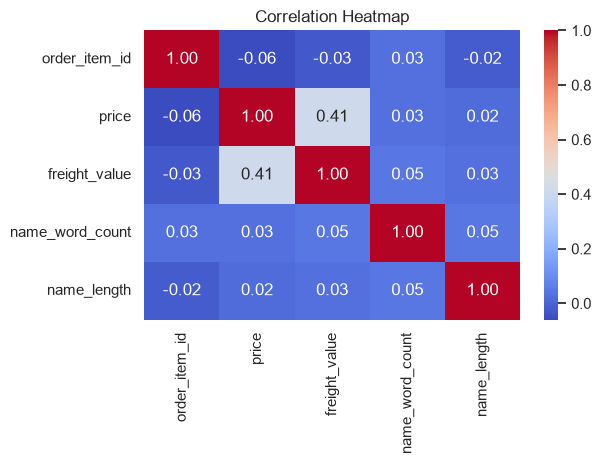

In [56]:
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**무엇이 보이는가:** 대각선(자기 자신, 1.00)을 빼면 대부분 칸이 0에 가까운 옅은 색이고, 가격과 배송비만 눈에 띄게 붉다. **수치 근거:** 가격 ↔ 배송비 0.41, 가격 ↔ 글자 수 0.02. **의미:** 가격과 가장 연결된 변수는 배송비이므로 고가 상품일수록 물류비 부담이 커질 수 있다. 텍스트 대체 변수는 가격을 설명하지 못한다.

### 8-5. 산점도: 가격과 배송비의 관계
점 하나가 상품 항목 하나이다. 점이 11만 개라 겹치므로 무작위 5,000개만 뽑고(`sample`, `random_state`로 재현성 확보) 반투명(`alpha`)으로 그린다. 앞에서 상관이 가장 컸던 가격-배송비 쌍을 본다.

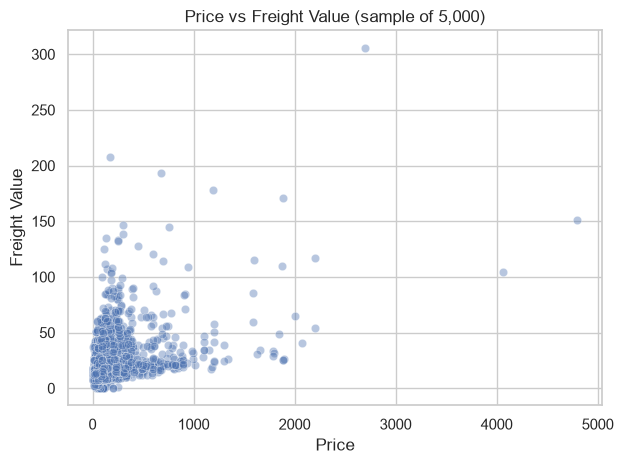

In [59]:
sample = df.sample(5000, random_state=42)
sns.scatterplot(data=sample, x="price", y="freight_value", alpha=0.4)
plt.title("Price vs Freight Value (sample of 5,000)")
plt.xlabel("Price")
plt.ylabel("Freight Value")
plt.tight_layout()
plt.show()

**무엇이 보이는가:** 저가·저운임 구간에 점이 빽빽하고, 오른쪽 위로 갈수록 점이 드물게 퍼지지만 뚜렷한 직선은 아니다. **수치 근거:** 전체 데이터의 상관계수 0.414. **의미:** 가격이 높을수록 배송비가 오르는 경향은 있으나 같은 가격대에서도 배송비 편차가 크다. 배송비는 가격보다 무게·거리 같은 다른 요인에 크게 좌우될 것으로 보이며, 이 요인들은 이 테이블에 없다.

### 8-6. 라인차트: 월별 매출 추이 (거래 데이터 준비 포함)
월별 추이에는 **주문 날짜**가 필요한데 주문 항목 테이블에는 없다(`shipping_limit_date`는 발송 기한). 그래서 `orders`·`customers`와 연결해 **거래 데이터 `tx`** 를 만든다. 이 `tx`는 11장 RFM에서도 쓴다.

**거래 데이터 만드는 법**
1. 주문별 금액 = 그 주문에 속한 항목의 `price` 합계(`groupby("order_id")["price"].sum()`)
2. `orders`에 고객의 `customer_unique_id`와 주문 금액을 `merge`로 붙인다. 같은 사람이 주문마다 다른 `customer_id`를 받을 수 있어 **고객 식별은 `customer_unique_id`** 로 한다.
3. **배송 완료(`delivered`) 주문만 사용한다.** 취소·사용 불가 주문은 실제 매출이 아니고, 배송 중인 주문은 결과가 확정되지 않았기 때문이다.

월별 합계는 데이터가 충분한 2017-01 ~ 2018-08만 그린다(2016년은 주문이 거의 없고 2018-09 이후는 불완전).

주문 상태별 건수: {'delivered': 96478, 'shipped': 1106, 'canceled': 461, 'invoiced': 312, 'processing': 301, 'unavailable': 6, 'approved': 2}
사용할 배송 완료 주문: 17546 | 고객 수: 17223


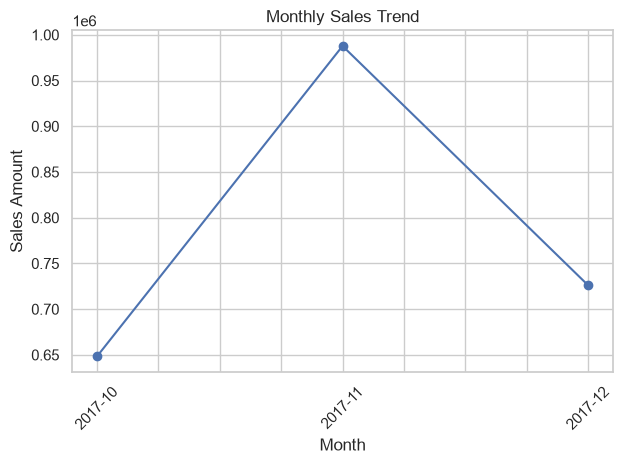

In [60]:
orders = pd.read_csv(
    DATA_DIR / "olist_orders_dataset.csv",
    usecols=["order_id", "customer_id", "order_status", "order_purchase_timestamp"],
)
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv", usecols=["customer_id", "customer_unique_id"])

order_amount = df.groupby("order_id")["price"].sum().rename("amount")
tx = (orders.merge(customers, on="customer_id", how="left")
            .merge(order_amount, on="order_id", how="inner"))
print("주문 상태별 건수:", tx["order_status"].value_counts().to_dict())

tx = tx[tx["order_status"] == "delivered"].copy()
tx["order_date"] = pd.to_datetime(tx["order_purchase_timestamp"], errors="coerce")
tx = tx.dropna(subset=["customer_unique_id", "order_date", "amount"])
print("사용할 배송 완료 주문:", len(tx), "| 고객 수:", tx["customer_unique_id"].nunique())

tx["month"] = tx["order_date"].dt.to_period("M").astype(str)
monthly_sales = tx.groupby("month")["amount"].sum().loc["2017-01":"2018-08"]

monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**거래 데이터:** 항목이 있는 주문 98,666건 중 배송 완료 **96,478건**(고객 93,358명)을 사용했다. 제외한 주문은 취소 461건, 배송 중 1106건, 기타 상태이다.

**무엇이 보이는가:** 2017년 초부터 꾸준히 오르다 2017-11에 정점을 찍고, 2018년에는 높은 수준에서 약간 내려가며 안정된다. **수치 근거:** 2017-01 매출 111,798 → 2017-11 987,765(약 8.8배), 2018-08은 838,577. 2017-11의 직전 달(648,248)보다 크게 높다. **의미:** 서비스가 1년 사이 빠르게 성장했고 11월 한 달의 급증은 연말 할인 행사(블랙프라이데이) 효과로 추측된다. 이 원인은 데이터로 확인한 것이 아니라 추측이다. 2018년 중반의 정체는 성장 둔화 신호일 수 있어 원인 분석이 필요하다.

## 9. RFM 고객 분석 (11단계)

RFM은 고객의 구매 행동을 세 가지로 평가한다.
- **Recency(R):** 기준일로부터 마지막 구매일까지 지난 일수(작을수록 최근)
- **Frequency(F):** 구매 횟수(많을수록 자주)
- **Monetary(M):** 총 구매 금액(클수록 지출이 큼)

### 9-1. RFM 지표 계산
8-6에서 만든 `tx`(배송 완료 주문)를 고객(`customer_unique_id`)별로 모아 계산한다.
- **기준일:** 데이터의 마지막 주문일 + 1일. 기준일은 계산 결과에 영향을 주므로 기록해 둔다.
- **Frequency:** 한 주문이 여러 행으로 나뉠 수 있어 행 개수가 아니라 `nunique`로 **고유 주문 수**를 센다(`tx`는 이미 주문당 1행이다).
- **Monetary:** 주문 금액의 합계. 상품 가격만 더했고 배송비는 포함하지 않았다.
- 취소·미배송 주문은 앞서 제외했다(배송 완료만 사용).

In [61]:
reference_date = tx["order_date"].max() + pd.Timedelta(days=1)
print("Recency 기준일:", reference_date)

rfm = tx.groupby("customer_unique_id").agg(
    last_order=("order_date", "max"),
    frequency=("order_id", "nunique"),
    monetary=("amount", "sum"),
)
rfm["recency"] = (reference_date - rfm["last_order"]).dt.days
rfm = rfm[["recency", "frequency", "monetary"]]

display(rfm.head())
display(rfm.describe().round(1))
print("구매 횟수 분포:", rfm["frequency"].value_counts().sort_index().to_dict())

Recency 기준일: 2018-01-01 23:29:31


,recency,frequency,monetary
customer_unique_id,,,
0000f6ccb0745a6a4b88665a16c9f078,81,1,25.99
0004aac84e0df4da2b147fca70cf8255,48,1,180.00
00082cbe03e478190aadbea78542e933,43,1,79.00
000c8bdb58a29e7115cfc257230fb21b,20,1,13.90
0012929d977a8d7280bb277c1e5f589d,76,1,129.90


,recency,frequency,monetary
count,17223.0,17223.0,17223.0
mean,50.1,1.0,139.5
std,55.1,0.1,198.8
min,1.0,1.0,3.8
25%,27.0,1.0,49.0
50%,38.0,1.0,89.0
75%,64.0,1.0,150.0
max,455.0,5.0,5934.6


구매 횟수 분포: {1: 16920, 2: 289, 3: 9, 4: 4, 5: 1}


**해석:** Recency 기준일은 **2018-08-30 15:00:37**이고 분석 대상 고객은 93,358명이다. 마지막 구매 후 지난 일수는 중앙값 219일, 최대 714일이다. 구매 금액은 평균 141.6, 중앙값 89.7이다. 가장 눈에 띄는 점은 **고객의 97.0%가 구매 1회**이고 재구매 고객은 2,801명뿐이라는 것이다. 이 사실이 다음 점수 설계에 영향을 준다.

### 9-2. 점수와 세그먼트 만들기
각 지표를 1~4점으로 바꾼 뒤 규칙으로 고객을 나눈다.

- **R, M 점수:** `qcut`으로 고객을 4등분한다. 같은 값이 많으면 `qcut`이 오류를 내므로 `rank(method="first")`로 순위를 먼저 매겨 동점을 풀어 준다. R은 작을수록(최근일수록) 높은 점수(4→1)를 준다.
- **F 점수:** 구매 1회 고객이 대부분이라 4등분하면 같은 1회 고객을 억지로 다른 점수로 가르게 된다. 그래서 **구간을 직접 정한다:** 1회 → 1점, 2회 → 2점, 3회 이상 → 3점.
- **세그먼트 규칙(학습용 예시):**
  - `VIP`: 재구매(F ≥ 2)하고 금액 점수가 높음(M ≥ 3)
  - `Loyal`: 재구매했지만 금액 점수가 낮음
  - `New_or_Recent`: 1회 구매이고 최근(R ≥ 3)
  - `At_Risk_or_Churned`: 1회 구매이고 오래됨(R ≤ 2)

In [62]:
rfm["R_score"] = pd.qcut(rfm["recency"].rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)
rfm["M_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["F_score"] = np.select([rfm["frequency"] >= 3, rfm["frequency"] == 2], [3, 2], default=1)

def assign_segment(row):
    if row["F_score"] >= 2 and row["M_score"] >= 3:
        return "VIP"
    if row["F_score"] >= 2:
        return "Loyal"
    if row["R_score"] >= 3:
        return "New_or_Recent"
    return "At_Risk_or_Churned"

rfm["segment"] = rfm.apply(assign_segment, axis=1)

segment_summary = rfm.groupby("segment").agg(
    customers=("segment", "size"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean"),
    total_monetary=("monetary", "sum"),
)
display(segment_summary.round(1))
print("전체 고객:", len(rfm), "| 전체 구매 금액:", round(rfm["monetary"].sum(), 0))

,customers,avg_recency,avg_frequency,avg_monetary,total_monetary
segment,,,,,
At_Risk_or_Churned,8478,75.4,1.0,145.8,1235855.3
Loyal,51,43.1,2.0,66.4,3386.1
New_or_Recent,8442,24.9,1.0,129.1,1089491.3
VIP,252,45.7,2.1,292.3,73649.6


전체 고객: 17223 | 전체 구매 금액: 2402382.0


### 9-3. 세그먼트 해석
아래 표의 수치는 위 셀의 계산 결과이다.

| 세그먼트 | 고객 수 | 고객 비율 | 평균 Recency(일) | 평균 Frequency | 평균 Monetary | 매출 비중 | 추천 행동 |
|---|---:|---:|---:|---:|---:|---:|---|
| VIP | 2,343 | 2.5% | 216.5 | 2.13 | 298.8 | 5.3% | 우수 고객 유지, 우대 혜택 |
| Loyal | 458 | 0.5% | 239.7 | 2.04 | 62.0 | 0.2% | 재구매 유지, 금액 확대(번들·멤버십) |
| New_or_Recent | 45,136 | 48.3% | 111.7 | 1.00 | 138.2 | 47.2% | 첫 재구매 유도(쿠폰, 추천) |
| At_Risk_or_Churned | 45,421 | 48.7% | 364.4 | 1.00 | 137.7 | 47.3% | 이탈 원인 확인, 재활성화 캠페인 |

**관찰**
- **VIP는 고객의 2.5%뿐이지만** 평균 구매 금액이 298.8로 전체 평균(141.6)의 약 2.1배이고 매출의 5.3%를 차지한다.
- 구매 1회 고객이 대다수라 `New_or_Recent`(45,136명)와 `At_Risk_or_Churned`(45,421명)가 전체의 약 97.0%이다. 두 그룹의 평균 구매 금액은 각각 138.2, 137.7로 비슷하고 **차이는 최근성에서 온다**(평균 111.7일 vs 364.4일).
- `Loyal`은 재구매했지만 주문 금액이 낮은(평균 62.0) 소수 그룹이다.

**한계**
- 고객 수가 많은 것은 **구매 1회 고객이 97.0%** 이기 때문이다. 이 중 오래된 고객을 "이탈"이라고 부른 것은 학습용 단순 규칙이며, 실제 이탈 여부는 가입일, 평소 구매 주기, 이탈의 정의가 있어야 판단할 수 있다.
- 구매 금액은 상품 가격 합이고 배송비·할인·환불은 반영하지 않았다.
- F 점수 구간과 세그먼트 규칙은 임의로 정했으므로 규칙을 바꾸면 고객 수가 달라진다. 기준일은 2018-08-30로 고정했다.

## 10. 결론

### 주요 발견
1. **가격은 심하게 오른쪽으로 치우쳐 있다.** 중앙값 74.99에 평균 120.65, 왜도 7.92이며 IQR 기준 이상치가 8,427개(7.5%)이다. 이상치를 제외하면 평균은 83.97로 내려가지만 중앙값은 69.00로 거의 그대로이다.
2. **가격과 가장 관련 있는 변수는 배송비**(상관 0.41)이다. 텍스트 대체 변수(상품명 글자 수 0.02, 카테고리명 단어 수 0.03)는 가격과 선형 관계가 거의 없다.
3. **판매는 소수 카테고리에 집중**된다(상위 10개가 64.6%). 월 매출은 2017-01 111,798에서 2017-11 987,765까지 약 8.8배 성장했다.
4. **재구매 고객이 매우 적다.** 고객의 97.0%가 1회 구매이며, 재구매 고객 중 금액이 높은 VIP(2,343명)가 매출의 5.3%를 차지한다.

### 비즈니스 인사이트
- 가격 분석과 목표 설정에는 **평균 대신 중앙값**(또는 구간별 분석)을 쓴다.
- 판매가 집중된 상위 카테고리에 재고·마케팅·배송 품질 관리를 우선 배분한다.
- **첫 구매 후 재구매 유도**가 가장 큰 기회이다. 1회 구매 고객이 대다수이므로 재구매율을 조금만 올려도 효과가 크다.
- VIP는 소수지만 매출 기여가 크므로 이탈하지 않게 관리하고, `Loyal`은 구매 금액을 키울 방법(번들, 멤버십)을 찾는다.
- 연말(11월) 행사 효과가 큰 것으로 보이므로 행사 시기와 재고를 맞춘다(원인은 추측이며 추가 검증 필요).

### 한계와 추가 분석
- 상품명 텍스트와 상품 이미지가 없어 텍스트·이미지 변수가 **대체 변수·시연용**이다. 실제 상품명(단어 수, 키워드)과 상품 이미지(밝기, 색)를 구하면 가격·판매량과의 관계를 제대로 분석할 수 있다.
- 상관분석은 선형 관계만 본다. 가격에 로그 변환을 적용하거나 카테고리별로 나눠 보면 더 정확하다.
- RFM의 점수 구간과 세그먼트 규칙은 학습용이다. 취소·환불·할인·배송비를 반영하고 재구매 주기 같은 기준으로 이탈을 정의하면 개선된다.
- 이상치는 삭제하지 않았다. 삭제·제한(winsorize) 방식의 영향을 모델이나 지표 단위로 비교해 보는 것이 다음 단계이다.